# Sentiment Analysis Using Machine Learning Algorithms

## Project Idea

Sentiment Analysis is a Natural Language Processing (NLP) task that aims to identify and understand the emotions or opinions expressed in written text. This project uses machine learning algorithms to analyze tweets and classify them into three sentiment categories: **Positive, Negative, and Neutral**.

The project uses a Twitter dataset containing text samples and their corresponding sentiment labels. The text data is cleaned and preprocessed to remove unnecessary information and prepare it for machine learning. TF-IDF is then used to convert the text into numerical features that can be understood by machine learning models.

Four machine learning algorithms are implemented and compared: Logistic Regression, Decision Tree, Random Forest, and Naive Bayes. Their performance is evaluated using multiple metrics to determine which model performs best for sentiment classification.

The main goal is to build a sentiment classification system that can automatically understand opinions in text and compare different machine learning approaches to find the most effective model.

## 1. Importing Libraries

In [1]:
# load libraries
import os
import re
import nltk
import string
import warnings

import joblib
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt

# NLTK libray
from collections import Counter
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.stem.isri import ISRIStemmer
from nltk.tokenize import word_tokenize

# SKlearn 
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                                classification_report, confusion_matrix, roc_curve, auc, roc_auc_score)

from sklearn.preprocessing import label_binarize

# for merge dataset
stop_words = set(stopwords.words('english'))

# Stemmer for two langs
stemmer = SnowballStemmer('english')
arabic_stemmer = ISRIStemmer()


# Set plot style
plt.style.use('seaborn-v0_8-colorblind')
sns.set_palette('husl')

# seed
np.random.seed(42)

# filter warnings
warnings.filterwarnings('ignore')

## 2. Loading the Dataset

In [2]:
# load dataset 
path = '/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_training.csv'
data = pd.read_csv(path, header=None)

# copy dataset 
df = data.copy()


print(f'Columns: {df.columns}')

# check missing value
print(f'\n\nMissing Value: {df.isnull().sum()}')

# INFO
print(f'\n\nInformation:\n {df.info()}')
df.head()

Columns: Index([0, 1, 2, 3], dtype='int64')


Missing Value: 0      0
1      0
2      0
3    686
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       74682 non-null  int64 
 1   1       74682 non-null  object
 2   2       74682 non-null  object
 3   3       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


Information:
 None


,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


## 3. Renaming Dataset Columns

In [3]:
# Rename columns
df.columns = ['id', 'game', 'sentiment', 'text']

print(f"New columns: \n{df.columns}")

New columns: 
Index(['id', 'game', 'sentiment', 'text'], dtype='object')


In [4]:
df.head()

,id,game,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [5]:
unique_labels = df["sentiment"].unique()

print(f'Classes: {unique_labels}')

Classes: ['Positive' 'Neutral' 'Negative' 'Irrelevant']


## 4. Data Cleaning

In [6]:
# clean missing vals
df = df.dropna(subset=['text', 'sentiment'])
df.drop_duplicates(inplace=True)

print(f'\n\nMissing Value: {df.isnull().sum()}')
print(f'\nDuplicated: {df.duplicated().sum()}')



Missing Value: id           0
game         0
sentiment    0
text         0
dtype: int64

Duplicated: 0


## 5. Displaying the Dataset

This step displays the first five rows of the dataset after renaming the columns.

It helps us verify that the column names were changed correctly and understand how the dataset records are organized.

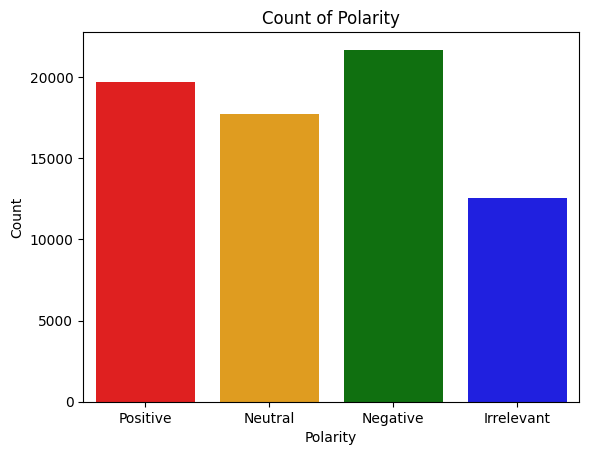

In [7]:
# Counter of sentiment 
COLORS = ['red', 'orange', 'green', 'blue']
sns.countplot(df, x= 'sentiment', palette= COLORS)

plt.xlabel("Polarity")
plt.ylabel("Count")
plt.title("Count of Polarity")

plt.show()

## 6. Text Preprocessing

Raw tweets may contain unnecessary information such as URLs, punctuation, special characters, numbers, and common words that do not contribute much to sentiment classification.

In this step, we define two preprocessing functions:

- **Pro_text():** Converts text to lowercase, removes URLs, bracketed content, punctuation, special characters, and numbers, and removes stop words.
- **stem_text():** Tokenizes the cleaned text and applies stemming using the Snowball Stemmer to reduce words to their root-like forms.

These functions are applied to the text column to prepare the tweets for feature extraction and model training.

In [8]:
# Processing of text 
def Pro_text(text):
    text = text.lower()
    punc = r'https?://\S+|www\.\S+|\[.*?\]|[^a-zA-Z\s]+|\w*\d\w*'
    text = re.sub(punc, '', text)

    # split text 
    filtered_words = [w for w in text.split() if w not in stop_words]

    return ' '.join(filtered_words).strip()

def stem_text(text):
    words = word_tokenize(text)

    stemmed_word = []
    for w in words:
        stemmed_word.append(stemmer.stem(w))

    return ' '.join(stemmed_word)


# Apply Preprocessing 
df['text'] = df['text'].apply(Pro_text)
df['text'][:5]

# apply stem
df['text'] = df['text'].apply(stem_text)
df['text'][:5]

0     im get borderland murder
1             come border kill
2       im get borderland kill
3    im come borderland murder
4     im get borderland murder
Name: text, dtype: object

## 7. Word Frequency Analysis and Sentiment Encoding

In [9]:
# count word accurences 
word_count = Counter(' '.join(df['text']).split())

# convert to dataframe
words_df = pd.DataFrame(list(word_count.items()), columns= ['words', 'Frequency'])

# sort dataframe
words_df = words_df.sort_values(by='Frequency',
                                ascending=False).reset_index(drop= True)

words_df.insert(0, 'Rank', words_df.index+1)
words_df.head()

# Generating wordcloud
def generate_wordcloud(text_input, title=""):
    cloud = WordCloud(width=1500, height=800, max_words= 500,
                      background_color='black', colormap="coolwarm")
    WORDCOLUD = cloud.generate(text_input)

    plt.figure(figsize=(10,8))
    plt.imshow(WORDCOLUD, interpolation='bilinear')
    plt.axis('off')

    plt.title(title, fontsize=20)
    plt.tight_layout()
    plt.show()


df = df[df['sentiment'].str.lower() != 'irrelevant']

sentiment_mapping = {'Negative':0, 'Neutral': 1, 'Positive': 2}
df['Polarity'] = df['sentiment'].map(sentiment_mapping)

df.head()

,id,game,sentiment,text,Polarity
0,2401,Borderlands,Positive,im get borderland murder,2
1,2401,Borderlands,Positive,come border kill,2
2,2401,Borderlands,Positive,im get borderland kill,2
3,2401,Borderlands,Positive,im come borderland murder,2
4,2401,Borderlands,Positive,im get borderland murder,2


## 8. Visualizing Words by Sentiment

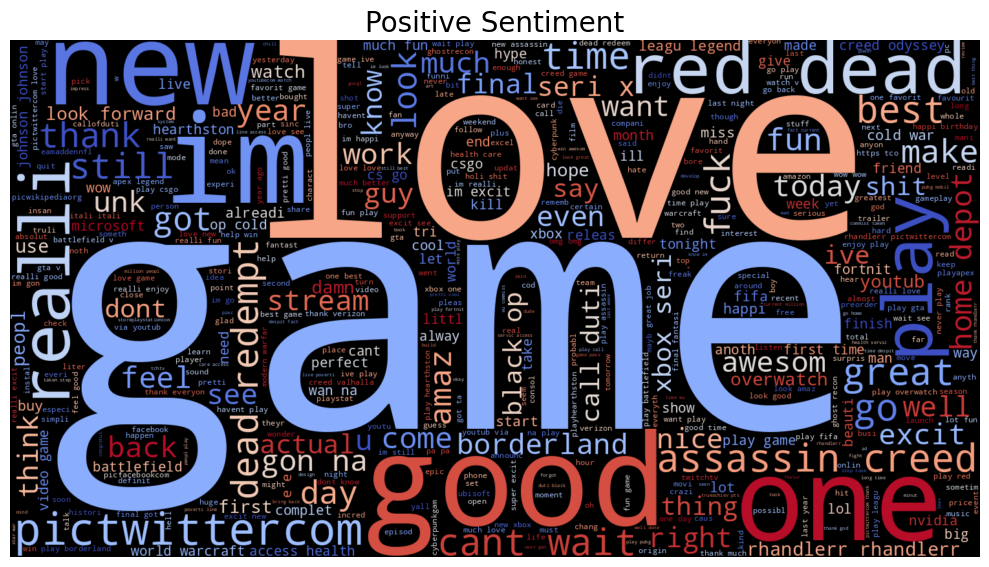

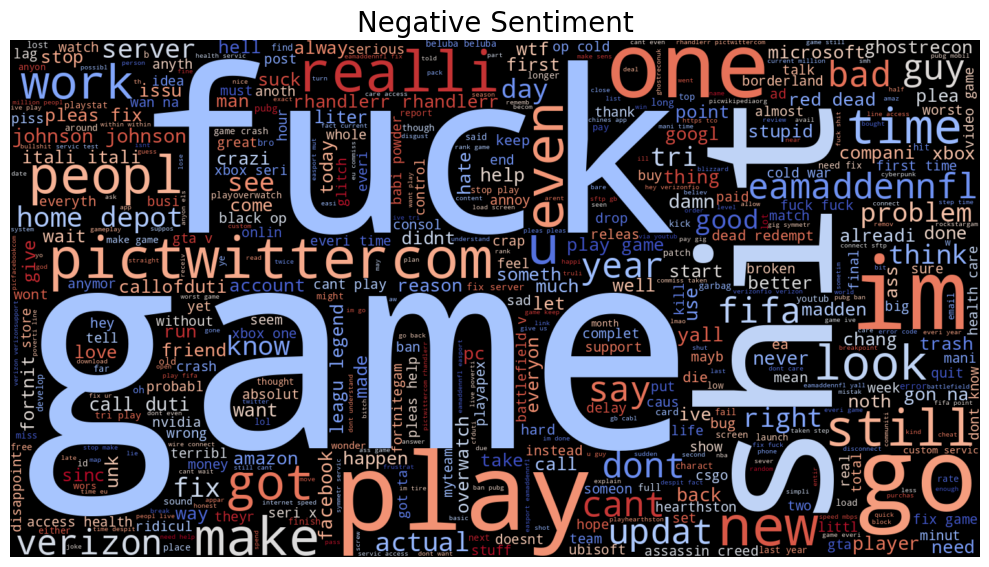

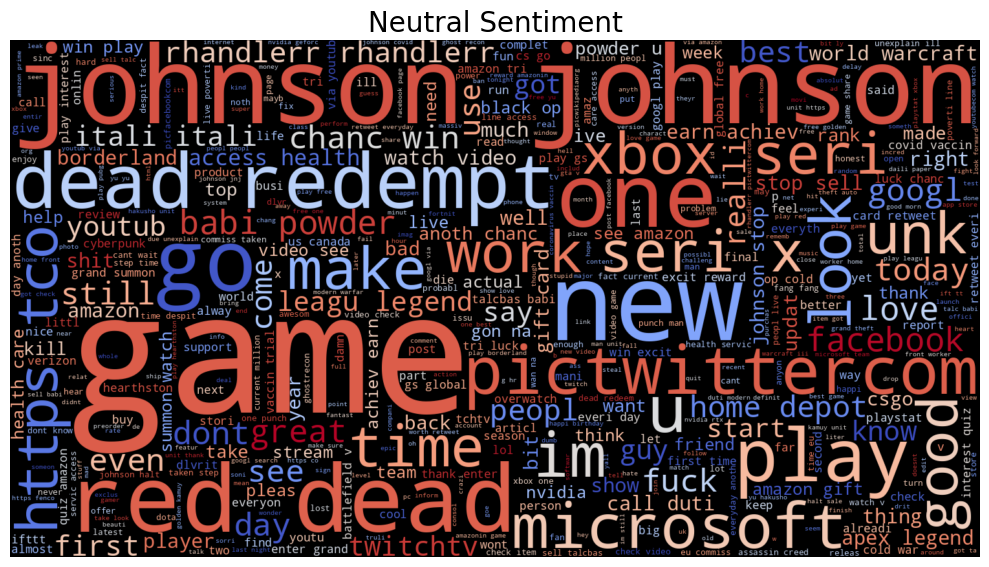

In [10]:
# show Positive word cloud
positive_words = ' '.join(df[df['Polarity'] == 2]['text'])
Negative_words = ' '.join(df[df['Polarity'] == 0]['text'])
Neutral_words = ' '.join(df[df['Polarity'] == 1]['text'])

generate_wordcloud(positive_words, title= 'Positive Sentiment')
generate_wordcloud(Negative_words, title= 'Negative Sentiment')
generate_wordcloud(Neutral_words, title= 'Neutral Sentiment')

## 9. Exploring Feature Distributions

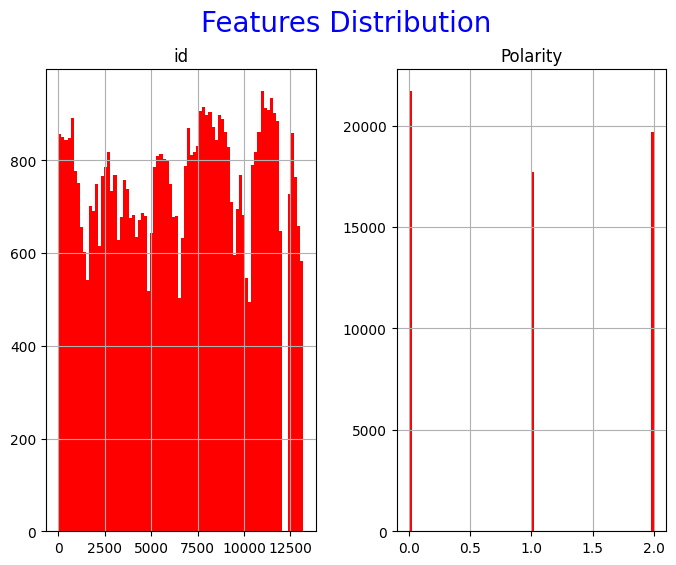

In [11]:
# historgram 
df.hist(figsize=(8,6), bins=80, color='red')
plt.suptitle("Features Distribution", fontsize= 20, color='blue')

plt.show()

## 10. Sentiment Percentage Distribution

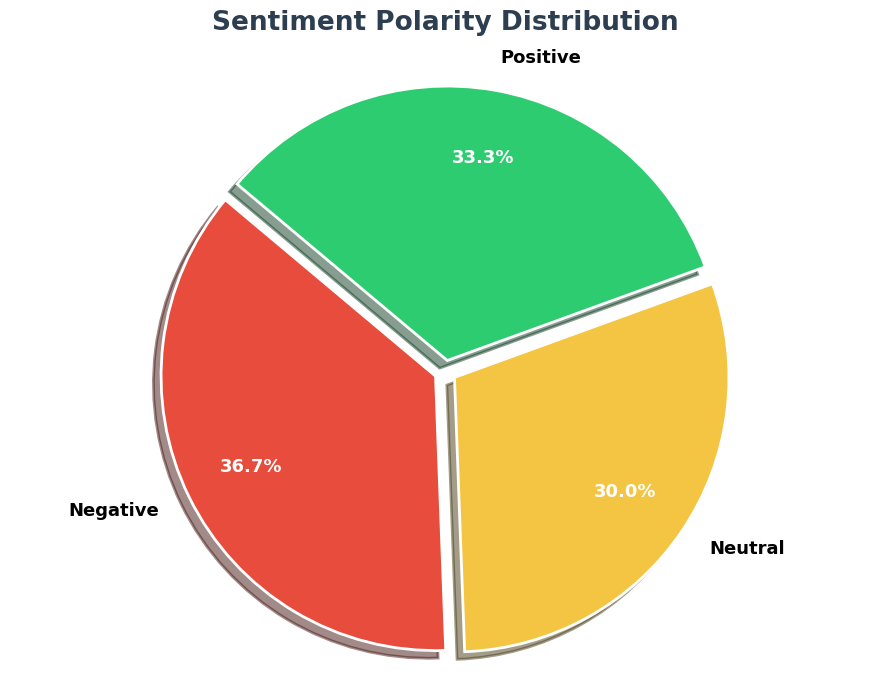

In [12]:
# Count sentiment classes
count_pol = df['sentiment'].value_counts()

# Define sentiment order
labels = ['Negative', 'Neutral', 'Positive']
count_pol = count_pol.reindex(labels, fill_value=0)

# Colors
colors = ['#E74C3C', '#F4C542', '#2ECC71']

# Create figure
fig, ax = plt.subplots(figsize=(9, 7))

# Pie chart
wedges, texts, autotexts = ax.pie(
    count_pol,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140,
    explode=(0.04, 0.04, 0.04),
    shadow=True,
    pctdistance=0.75,
    labeldistance=1.12,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 13,
        'fontweight': 'bold'
    }
)

# Style percentage labels
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(13)
    autotext.set_fontweight('bold')

# Title
ax.set_title(
    'Sentiment Polarity Distribution',
    fontsize=19,
    fontweight='bold',
    color='#2C3E50',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

## 11. Splitting the Dataset

In [13]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['sentiment'], test_size=0.3, random_state=42)

print(f'X Train shape: {X_train.shape}')
print(f'X Test shape: {X_test.shape}')
print(f'y Train shape: {y_train.shape}')
print(f'y Test shape: {y_test.shape}')

X Train shape: (41383,)
X Test shape: (17736,)
y Train shape: (41383,)
y Test shape: (17736,)


## 12. Text Feature Extraction Using TF-IDF

In [14]:
# Initialize the TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

## 13. Logistic Regression Model

Logistic Regression is a supervised machine learning classification algorithm used to predict categorical outcomes.

In this project, Logistic Regression is trained on the TF-IDF feature vectors to classify tweets into Negative, Neutral, or Positive sentiment.

The model is configured with L2 regularization, the SAG solver, and a maximum of 2000 iterations.

After training, the model predicts sentiment labels for the test data and prediction probabilities. We then evaluate its performance using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix.

LOGISTIC REGRESSION EVALUATION
Train Accuracy  : 0.8508
Test Accuracy   : 0.7842
Precision Macro : 0.7814
Recall Macro    : 0.7812
F1 Score Macro  : 0.7813

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.82      0.82      6595
     Neutral       0.74      0.74      0.74      5242
    Positive       0.79      0.78      0.79      5899

    accuracy                           0.78     17736
   macro avg       0.78      0.78      0.78     17736
weighted avg       0.78      0.78      0.78     17736



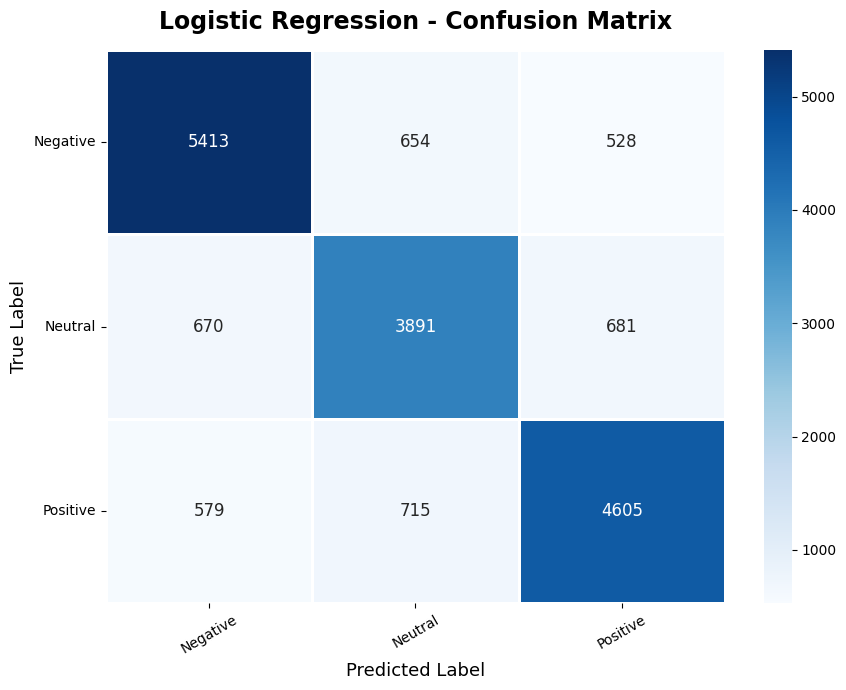

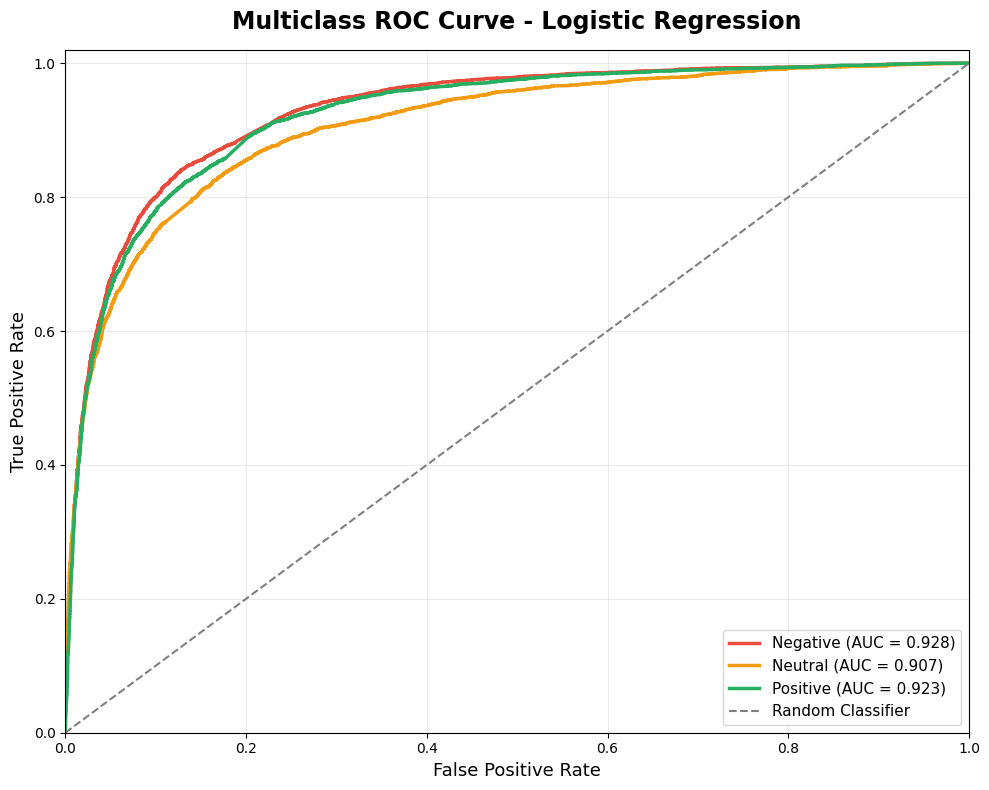

In [15]:
# Logistic Regression Model
model_ls = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='sag',
    max_iter=2000,
    random_state=42
)

# Training
model_ls.fit(X_train_tfidf, y_train)

# Predictions
y_pred_r = model_ls.predict(X_test_tfidf)
y_prob = model_ls.predict_proba(X_test_tfidf) # Prediction probabilities

print("=" * 50)
print("LOGISTIC REGRESSION EVALUATION")
print("=" * 50)

print(f"Train Accuracy  : {model_ls.score(X_train_tfidf, y_train):.4f}")
print(f"Test Accuracy   : {accuracy_score(y_test, y_pred_r):.4f}")

print(f"Precision Macro : {precision_score(y_test, y_pred_r, average='macro'):.4f}")
print(f"Recall Macro    : {recall_score(y_test, y_pred_r, average='macro'):.4f}")
print(f"F1 Score Macro  : {f1_score(y_test, y_pred_r, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_r, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_r, labels=model_ls.classes_)
plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='white',
             xticklabels=model_ls.classes_, yticklabels=model_ls.classes_, annot_kws={'size': 12})

plt.title('Logistic Regression - Confusion Matrix',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Predicted Label', fontsize=13)
plt.ylabel('True Label', fontsize=13)
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Binarize target labels
classes = model_ls.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

n_classes = len(classes)

# Store ROC results
fpr = {}
tpr = {}
roc_auc = {}

# Calculate ROC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot AUC Curve
colors = ['#E74C3C', '#F39C12', '#27AE60', '#3498DB']

plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, linewidth=2.5, label=f'{classes[i]} (AUC = {roc_auc[i]:.3f})')

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray',
          linewidth=1.5, label='Random Classifier')

plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title(
    'Multiclass ROC Curve - Logistic Regression',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.25)
plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.tight_layout()
plt.show()

## 14. Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions by following a sequence of decision rules.

The model divides the data into smaller groups based on features until it reaches a prediction.

In this project, GridSearchCV is used to search for the best Decision Tree parameters, including:

- **Criterion:** Gini impurity or Entropy.
- **Max Depth:** Controls the maximum depth of the tree.

After finding the best parameters, the model is trained and used to predict the sentiment of the test tweets. Its performance is evaluated using several classification metrics.

DECISION TREE EVALUATION
Train Accuracy  : 0.6491
Test Accuracy   : 0.6041
Precision Macro : 0.6911
Recall Macro    : 0.5812
F1 Score Macro  : 0.5759

Classification Report:
              precision    recall  f1-score   support

    Negative       0.51      0.92      0.66      6595
     Neutral       0.77      0.32      0.45      5242
    Positive       0.79      0.51      0.62      5899

    accuracy                           0.60     17736
   macro avg       0.69      0.58      0.58     17736
weighted avg       0.68      0.60      0.58     17736



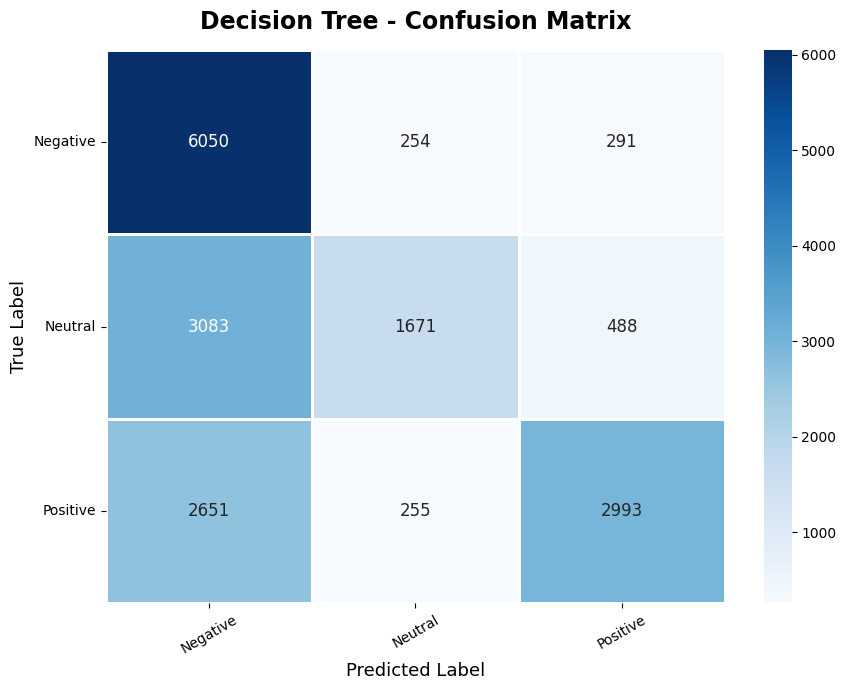

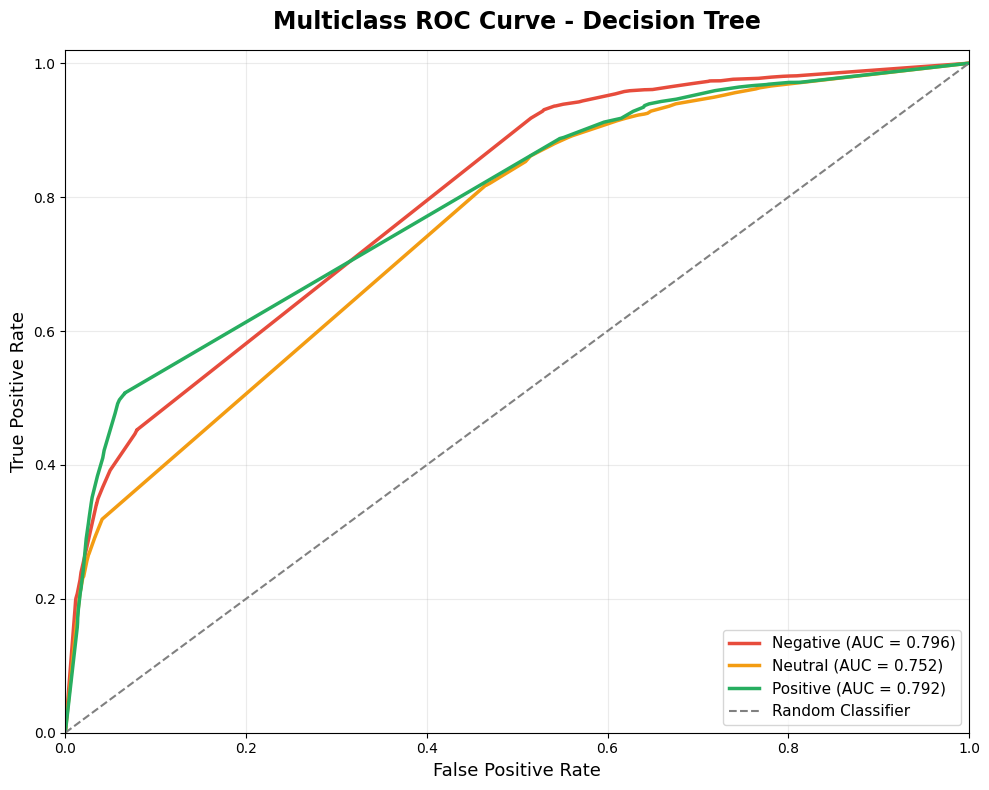

In [16]:
# Decision Tree Model
tree1 = DecisionTreeClassifier(random_state=42)

params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 2, 3, 10, 15, 20, 35, 30],
}

tree_model = GridSearchCV(tree1, params)
tree_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_tree = tree_model.predict(X_test_tfidf)
y_prob = tree_model.predict_proba(X_test_tfidf) # Prediction probabilities

print("=" * 50)
print("DECISION TREE EVALUATION")
print("=" * 50)

print(f"Train Accuracy  : {tree_model.score(X_train_tfidf, y_train):.4f}")
print(f"Test Accuracy   : {accuracy_score(y_test, y_pred_tree):.4f}")

print(f"Precision Macro : {precision_score(y_test, y_pred_tree, average='macro'):.4f}")
print(f"Recall Macro    : {recall_score(y_test, y_pred_tree, average='macro'):.4f}")
print(f"F1 Score Macro  : {f1_score(y_test, y_pred_tree, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tree, labels=tree_model.classes_)
plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='white',
             xticklabels=tree_model.classes_, yticklabels=tree_model.classes_, annot_kws={'size': 12})

plt.title('Decision Tree - Confusion Matrix',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Predicted Label', fontsize=13)
plt.ylabel('True Label', fontsize=13)
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Binarize target labels
classes = tree_model.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

n_classes = len(classes)

# Store ROC results
fpr = {}
tpr = {}
roc_auc = {}

# Calculate ROC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot AUC Curve
colors = ['#E74C3C', '#F39C12', '#27AE60', '#3498DB']

plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, linewidth=2.5, label=f'{classes[i]} (AUC = {roc_auc[i]:.3f})')

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray',
          linewidth=1.5, label='Random Classifier')

plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title(
    'Multiclass ROC Curve - Decision Tree',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.25)
plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.tight_layout()
plt.show()

## 15. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction performance and reduce the risk of overfitting.

Instead of relying on one tree, it builds several trees and combines their predictions to produce the final classification.

In this project, GridSearchCV searches for the best Random Forest parameters, including:

- **N_estimators:** The number of trees in the forest.
- **Max_depth:** The maximum depth of each tree.
- **Min_samples_split:** The minimum number of samples required to split a node.

The best model is used to predict the sentiment of the test tweets and evaluate its performance.

RANDOM FOREST EVALUATION
Train Accuracy  : 0.9740
Test Accuracy   : 0.9060
Precision Macro : 0.9072
Recall Macro    : 0.9042
F1 Score Macro  : 0.9051

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.92      0.92      6595
     Neutral       0.93      0.87      0.90      5242
    Positive       0.87      0.93      0.90      5899

    accuracy                           0.91     17736
   macro avg       0.91      0.90      0.91     17736
weighted avg       0.91      0.91      0.91     17736



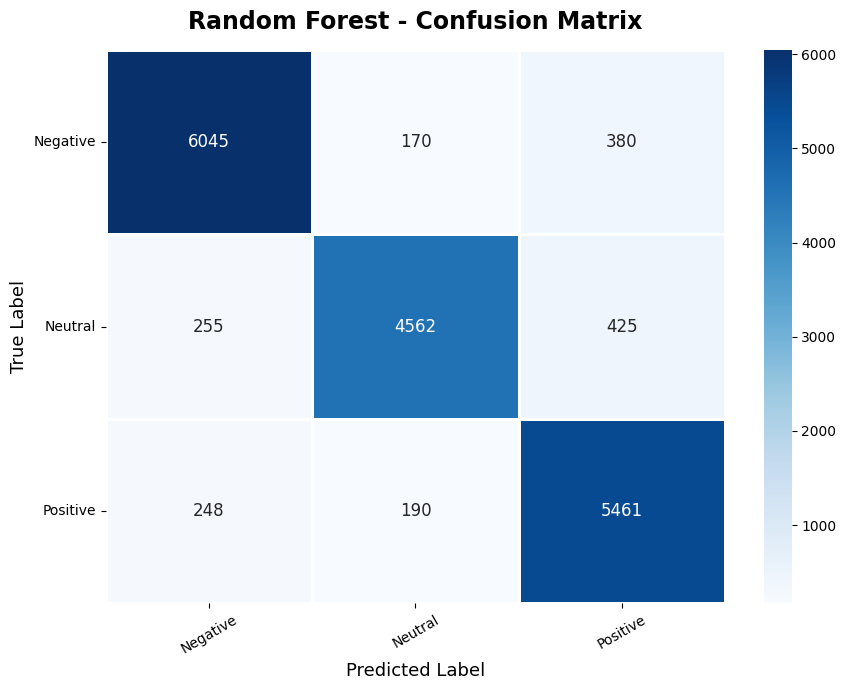

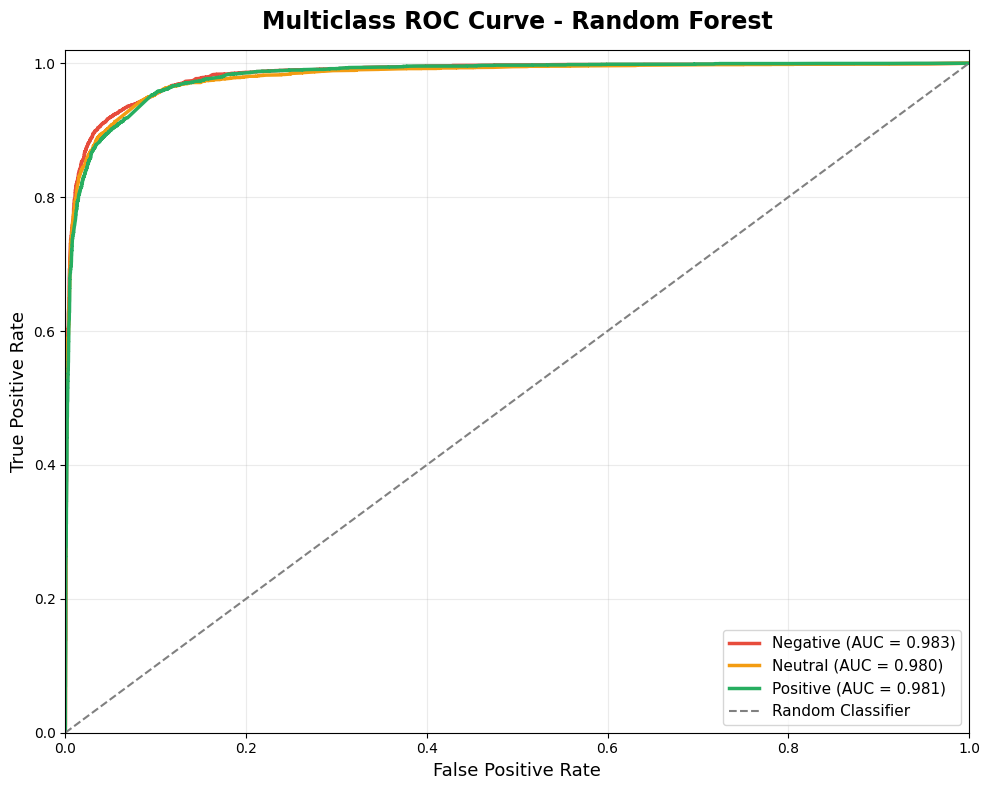

In [17]:
# Random Forest Model
rf_model = RandomForestClassifier(random_state=42)

par_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

randf_model = GridSearchCV(rf_model, par_rf)
randf_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_lr = randf_model.predict(X_test_tfidf)
y_prob = randf_model.predict_proba(X_test_tfidf) # Prediction probabilities

print("=" * 50)
print("RANDOM FOREST EVALUATION")
print("=" * 50)

print(f"Train Accuracy  : {randf_model.score(X_train_tfidf, y_train):.4f}")
print(f"Test Accuracy   : {accuracy_score(y_test, y_pred_lr):.4f}")

print(f"Precision Macro : {precision_score(y_test, y_pred_lr, average='macro'):.4f}")
print(f"Recall Macro    : {recall_score(y_test, y_pred_lr, average='macro'):.4f}")
print(f"F1 Score Macro  : {f1_score(y_test, y_pred_lr, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=randf_model.classes_)
plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='white',
             xticklabels=randf_model.classes_, yticklabels=randf_model.classes_, annot_kws={'size': 12})

plt.title('Random Forest - Confusion Matrix',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Predicted Label', fontsize=13)
plt.ylabel('True Label', fontsize=13)
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Binarize target labels
classes = randf_model.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

n_classes = len(classes)

# Store ROC results
fpr = {}
tpr = {}
roc_auc = {}

# Calculate ROC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot AUC Curve
colors = ['#E74C3C', '#F39C12', '#27AE60', '#3498DB']

plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, linewidth=2.5, label=f'{classes[i]} (AUC = {roc_auc[i]:.3f})')

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray',
          linewidth=1.5, label='Random Classifier')

plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title(
    'Multiclass ROC Curve - Random Forest',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.25)
plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.tight_layout()
plt.show()

## 16. Naive Bayes Classifier

Naive Bayes is a probabilistic machine learning algorithm based on Bayes' theorem.

It predicts a class by calculating the probability that an input belongs to each class. It assumes that features are conditionally independent given the class.

Multinomial Naive Bayes is commonly used for text classification because it works well with word-based features such as TF-IDF.

In this step, GridSearchCV tests different values of the alpha parameter, which controls smoothing and helps prevent zero probabilities.

The best Naive Bayes model is evaluated using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix.

NAIVE BAYES EVALUATION
Naive Bayes model best parameter: {'alpha': 0.1}
Naive Bayes model best score: 0.7861
------------------------------------------------------------
Train Accuracy  : 0.8526
Test Accuracy   : 0.7953
Precision Macro : 0.8031
Recall Macro    : 0.7887
F1 Score Macro  : 0.7922

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.87      0.81      6595
     Neutral       0.85      0.70      0.77      5242
    Positive       0.79      0.80      0.80      5899

    accuracy                           0.80     17736
   macro avg       0.80      0.79      0.79     17736
weighted avg       0.80      0.80      0.79     17736

------------------------------------------------------------


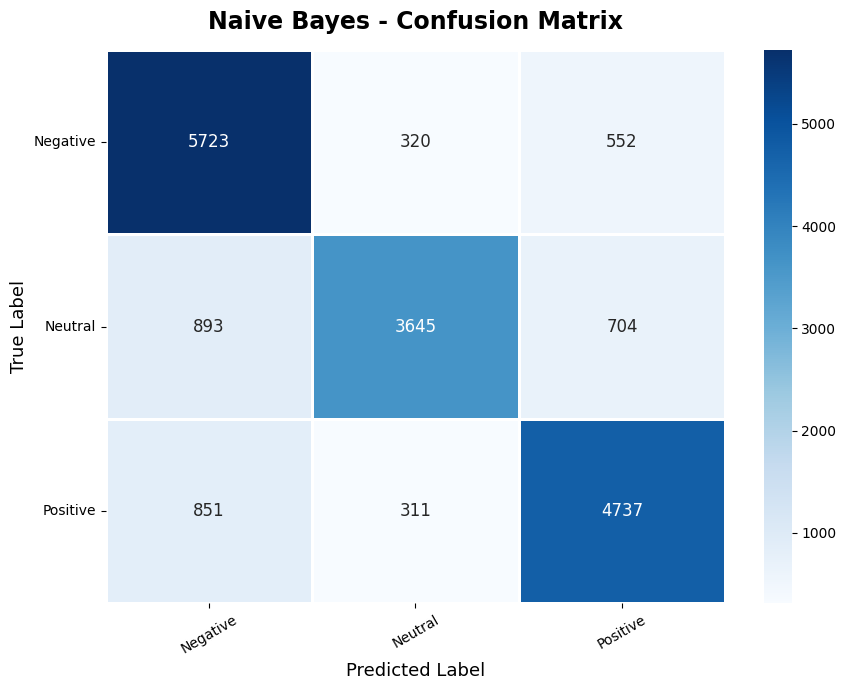

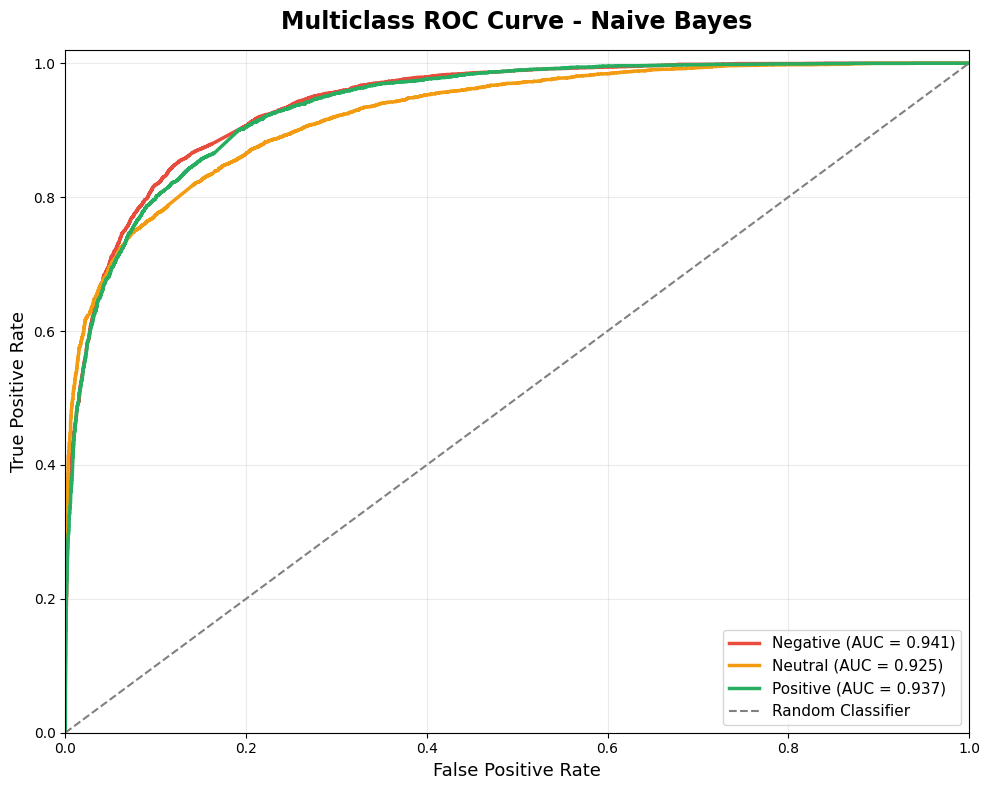

In [18]:
# Naive Bayes
NB_model = MultinomialNB()

param_NB = {
    'alpha': [0.1, 0.5, 1.0]
}

nb_model = GridSearchCV(NB_model, param_NB, cv=5)
nb_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_NB = nb_model.predict(X_test_tfidf)
y_prob = nb_model.predict_proba(X_test_tfidf) # Prediction probabilities

print("=" * 50)
print("NAIVE BAYES EVALUATION")
print("=" * 50)

print(f'Naive Bayes model best parameter: {nb_model.best_params_}')
print(f'Naive Bayes model best score: {nb_model.best_score_:.4f}')
print('-'*60)

print(f"Train Accuracy  : {nb_model.score(X_train_tfidf, y_train):.4f}")
print(f"Test Accuracy   : {accuracy_score(y_test, y_pred_NB):.4f}")

print(f"Precision Macro : {precision_score(y_test, y_pred_NB, average='macro'):.4f}")
print(f"Recall Macro    : {recall_score(y_test, y_pred_NB, average='macro'):.4f}")
print(f"F1 Score Macro  : {f1_score(y_test, y_pred_NB, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_NB, zero_division=0))
print('-'*60)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_NB, labels=nb_model.classes_)

plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='white',
             xticklabels=nb_model.classes_, yticklabels=nb_model.classes_, annot_kws={'size': 12})

plt.title('Naive Bayes - Confusion Matrix',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Predicted Label', fontsize=13)
plt.ylabel('True Label', fontsize=13)
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Binarize target labels
classes = nb_model.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

n_classes = len(classes)

# Store ROC results
fpr = {}
tpr = {}
roc_auc = {}

# Calculate ROC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot AUC Curve
colors = ['#E74C3C', '#F39C12', '#27AE60', '#3498DB']

plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, linewidth=2.5, label=f'{classes[i]} (AUC = {roc_auc[i]:.3f})')

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray',
          linewidth=1.5, label='Random Classifier')

plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title(
    'Multiclass ROC Curve - Naive Bayes',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.25)
plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.tight_layout()
plt.show()

## 17. Comparing the Machine Learning Models

After training the four classifiers, we collect each model and its predictions into one dictionary.

For each model, we calculate several evaluation metrics:

- **Accuracy:** The percentage of total predictions that are correct.
- **Precision:** How many predicted samples for a class are actually correct.
- **Recall:** How many actual samples of a class the model successfully identifies.
- **F1-score:** The harmonic mean of precision and recall.
- **ROC-AUC:** Measures how effectively the model distinguishes between classes.

Macro averaging calculates each class metric separately and then averages them, giving each sentiment class equal importance.

The results are stored in a DataFrame to make it easier to compare the four models.

In [19]:
# Model Predictions
models = {
    'Logistic Regression': (model_ls, y_pred_r),
    'Decision Tree': (tree_model, y_pred_tree),
    'Random Forest': (randf_model, y_pred_lr),
    'Naive Bayes': (nb_model, y_pred_NB)
}

# Store Results
results = []

for name, (model, y_pred) in models.items():

    y_prob_model = model.predict_proba(X_test_tfidf)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'ROC-AUC': roc_auc_score(
            y_test,
            y_prob_model,
            multi_class='ovr',
            average='macro',
            labels=model.classes_
        )
    })

# Create DataFrame
results_df = pd.DataFrame(results)

results_df = results_df.set_index('Model')

print("MODEL COMPARISON")
display(results_df.round(4))

MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7842,0.7814,0.7812,0.7813,0.9193
Decision Tree,0.6041,0.6911,0.5812,0.5759,0.7798
Random Forest,0.9060,0.9072,0.9042,0.9051,0.9816
Naive Bayes,0.7953,0.8031,0.7887,0.7922,0.9341


## 18. Accuracy Comparison

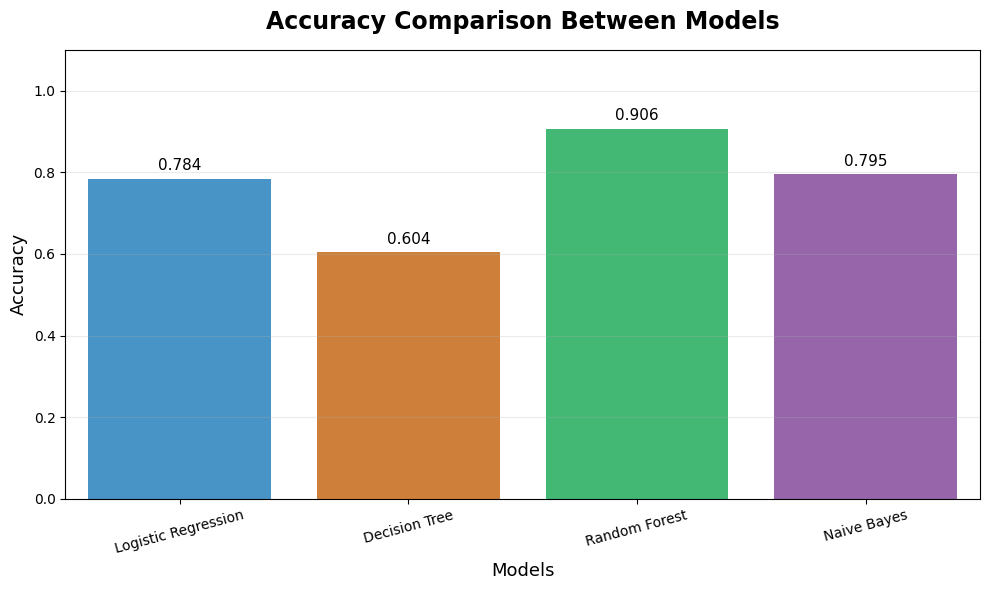

In [20]:
# Compare Accuracy
plt.figure(figsize=(10, 6))

colors = ['#3498DB', '#E67E22', '#2ECC71', '#9B59B6']
ax = sns.barplot(
    x=results_df.index,
    y=results_df['Accuracy'],
    hue=results_df.index,
    palette=colors,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=4, fontsize=11)

plt.title('Accuracy Comparison Between Models',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Models', fontsize=13)
plt.ylabel('Accuracy', fontsize=13)
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

## 19. Comparing Model Performance Using Multiple Metrics

<Figure size 1300x700 with 0 Axes>

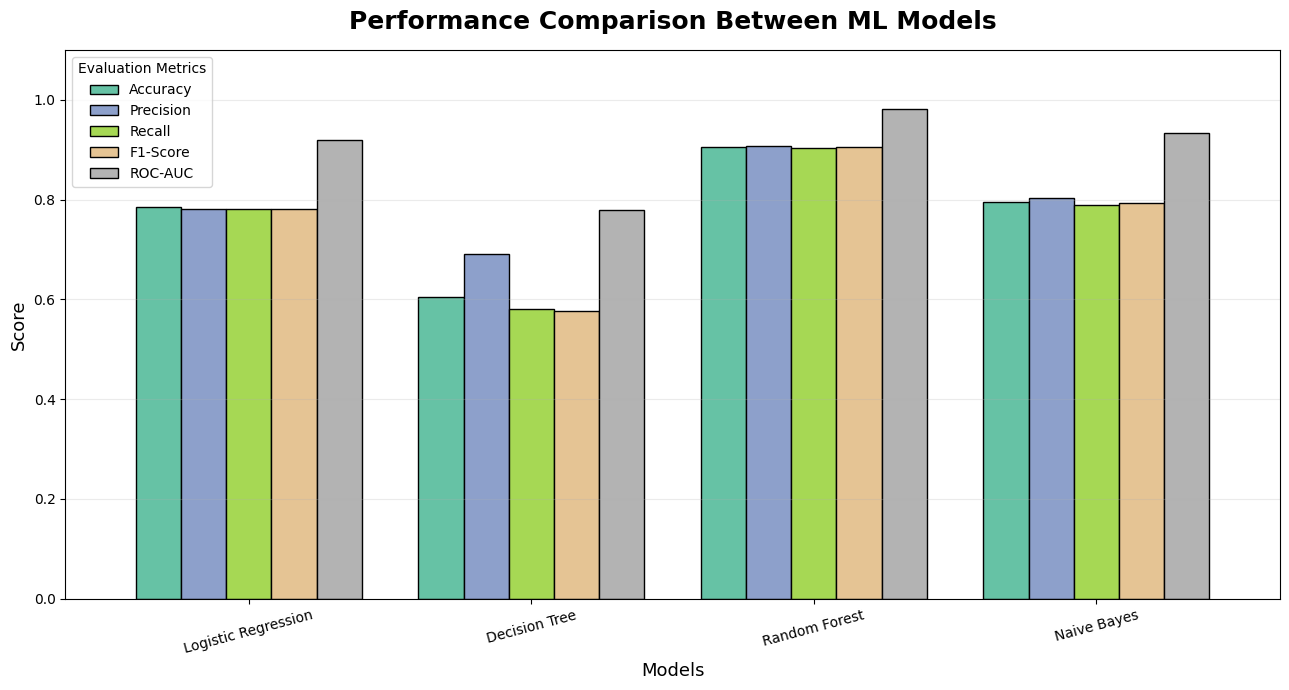

In [21]:
# Compare All Evaluation Metrics
plt.figure(figsize=(13, 7))

results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8,
    colormap='Set2',
    edgecolor='black'
)

plt.title('Performance Comparison Between ML Models',
          fontsize=18, fontweight='bold', pad=15)

plt.xlabel('Models', fontsize=13)
plt.ylabel('Score', fontsize=13)
plt.xticks(rotation=15)
plt.ylim(0, 1.1)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

## 20. Selecting the Best Performing Model

In [22]:
# Find best model for each metric
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

for metric in metrics:
    best_model = results_df[metric].idxmax()
    best_score = results_df[metric].max()

    print(f'Best {metric}: {best_model} ({best_score:.4f})')


# Overall ranking based on average metrics
results_df['Average Score'] = results_df[metrics].mean(axis=1)

print('\nOverall Model Ranking:')
display(
    results_df[['Average Score']]
    .sort_values(by='Average Score', ascending=False)
)

Best Accuracy: Random Forest (0.9060)
Best Precision: Random Forest (0.9072)
Best Recall: Random Forest (0.9042)
Best F1-Score: Random Forest (0.9051)
Best ROC-AUC: Random Forest (0.9816)

Overall Model Ranking:


,Average Score
Model,
Random Forest,0.920826
Naive Bayes,0.822677
Logistic Regression,0.809490
Decision Tree,0.646411


## 21. Saving the Trained Models (option)

<details>
<summary>Click Here to Show</summary> </br>

```python
joblib.dump(nb_model.best_estimator_, "naive_bayes_model.pkl")
joblib.dump(randf_model.best_estimator_, "RandomForset_model.pkl")
joblib.dump(tree_model.best_estimator_, "Tree_model.pkl")
joblib.dump(model_ls, "LogisiticRegression_model.pkl") 


## 22. Testing Sentiment Prediction on New Text


In [23]:
# test model
def predict_sentiment(text, model):
    vectorized_text = vectorizer.transform([text])
    pred = model.predict(vectorized_text)[0]
    return pred

sample_text = "I absolutely love this app! It's intuitive and works flawlessly."
predicted_sentiment = predict_sentiment(sample_text, model_ls)
print(f"Predicted Sentiment Logistic Regression: {predicted_sentiment}")
print('-'*60)

predicted_sentiment = predict_sentiment(sample_text, nb_model)
print(f"Predicted Sentiment NB: {predicted_sentiment}")
print('-'*60)

predicted_sentiment = predict_sentiment(sample_text, randf_model)
print(f"Predicted Sentiment Random Forest: {predicted_sentiment}")
print('-'*60)

predicted_sentiment = predict_sentiment(sample_text, tree_model)
print(f"Predicted Sentiment Decision Tree: {predicted_sentiment}")
print('-'*60)

Predicted Sentiment Logistic Regression: Positive
------------------------------------------------------------
Predicted Sentiment NB: Negative
------------------------------------------------------------
Predicted Sentiment Random Forest: Positive
------------------------------------------------------------
Predicted Sentiment Decision Tree: Positive
------------------------------------------------------------


## 23. Testing 

In [24]:
sample_text = "Nothing seems to matter anymore. Each day blends into the next, a dull cycle of repetition and meaningless effort. The dreams I once had now feel like distant memories, lost beneath the weight of disappointment. People smile, but it’s all so empty—just masks hiding the same quiet despair. I try to care, to feel something, but all that comes is exhaustion. The future looks as bleak as the past, and motivation feels like a foreign concept. It’s hard to believe things will ever change when everything around me feels broken and pointless. Maybe this is just how it ends—quietly fading."

models = [model_ls, nb_model, randf_model, tree_model]
name = ['Logistic Regression', 'Naive Bayes', 'Random Forset', 'Decisoin Tree']

for model, model_name in zip(models, name):
    predicted_sentiment = predict_sentiment(sample_text, model)
    
    print(f"Predicted Sentiment ({model_name}): {predicted_sentiment}")
    print('-'*60)


Predicted Sentiment (Logistic Regression): Neutral
------------------------------------------------------------
Predicted Sentiment (Naive Bayes): Neutral
------------------------------------------------------------
Predicted Sentiment (Random Forset): Negative
------------------------------------------------------------
Predicted Sentiment (Decisoin Tree): Negative
------------------------------------------------------------


### 24. Testing 

In [25]:
sample_text = """Technology has become an integral part of daily life, influencing nearly every aspect of how people live, work, and communicate. From the moment individuals wake up to the time they go to sleep, various technological devices and systems play a role in shaping their activities. The integration of technology into human routines has created a complex environment in which convenience, efficiency, and connectivity are balanced against concerns of dependence, data privacy, and digital fatigue. This text will examine the role of technology in modern life across key domains such as communication, work, education, healthcare, transportation, and leisure, with an aim to present a neutral, observational perspective.

Communication and Connectivity

One of the most visible impacts of technology has been in the field of communication. Mobile phones, instant messaging applications, email, and social media platforms have altered the way individuals and organizations exchange information. Communication is now faster, often immediate, and can transcend geographical boundaries. This has allowed for greater accessibility to information and increased global interconnectivity.

At the same time, these changes have shifted the expectations of communication. There is a growing trend toward responsiveness and availability, which has influenced both professional and personal interactions. The presence of multiple communication channels can also lead to fragmented attention and an increased volume of information, requiring individuals to develop strategies for managing digital correspondence.

Workplace Dynamics and Remote Access

Technology has reshaped work environments and processes. Many industries rely heavily on digital tools such as cloud computing, data analytics, and enterprise resource planning systems. These technologies contribute to greater efficiency in operations, improved decision-making, and streamlined communication within and between organizations.

Remote work, facilitated by video conferencing software, collaboration platforms, and secure virtual private networks (VPNs), has become more prevalent, especially after global events that disrupted traditional office-based work models. This shift has prompted organizations to reconsider workspace needs, employee management strategies, and performance metrics. It has also necessitated adaptations in cybersecurity and data protection protocols to account for distributed digital access.

However, the integration of technology in the workplace also introduces the need for continuous learning and adaptation. Workers must frequently update their skills to remain aligned with evolving software, systems, and protocols. This ongoing need for training reflects the dynamic nature of the technological landscape.

Education and Learning Environments

Educational institutions have adopted various technological solutions to support learning and administration. Learning management systems (LMS), virtual classrooms, and digital textbooks offer students flexible options for engaging with content. These tools enable access to a broad range of resources, including multimedia content, forums for discussion, and automated assessments.

Online learning, both synchronous and asynchronous, has expanded opportunities for education beyond traditional settings. It supports self-paced study and allows learners to pursue academic or professional goals while managing other responsibilities. Instructors, too, have access to tools for monitoring progress, customizing materials, and facilitating interactions.

Despite the advantages of digital education, technology also introduces challenges related to access, engagement, and academic integrity. Reliable internet connections, appropriate devices, and digital literacy are prerequisites that not all learners possess equally. Moreover, ensuring sustained attention in virtual learning environments requires thoughtful design and teaching strategies that leverage the strengths of the medium without over-relying on automation.

Healthcare and Medical Technology

The healthcare sector has experienced significant transformation due to technological innovations. Electronic health records (EHRs), diagnostic imaging, wearable monitoring devices, and telemedicine services have contributed to more accurate diagnoses, better record-keeping, and extended access to medical expertise. Patients can schedule appointments, access test results, and consult with providers without needing to visit a clinic in person.

Medical research also benefits from computational tools and data modeling, enabling faster analysis of trends, treatment outcomes, and drug efficacy. Genomic medicine and personalized healthcare are further examples of how technology is enabling more targeted interventions.

Nevertheless, the expansion of digital systems in healthcare also brings questions regarding patient data privacy, system interoperability, and the equitable distribution of technological advancements. The efficiency of digital tools is influenced by how they are implemented and maintained within specific health systems, as well as the training provided to professionals who use them.

Transportation and Mobility

Advancements in transportation technology affect both the movement of people and goods. Innovations include ride-sharing apps, real-time GPS navigation, autonomous vehicles, and electric mobility solutions. These developments aim to enhance convenience, reduce emissions, and improve safety on the roads.

For logistics and supply chain operations, technology facilitates inventory tracking, route optimization, and just-in-time delivery. These capabilities are particularly valuable in industries where timing and accuracy are critical to success.

The development and deployment of transportation technologies require infrastructure support, regulatory frameworks, and consumer adoption. Factors such as traffic data, environmental considerations, and energy sources influence how these technologies are integrated into existing systems. While they promise efficiency and modernization, their benefits are contingent on broader systemic adjustments.

Leisure, Media, and Entertainment

The consumption of media and entertainment is increasingly digital. Streaming services, online gaming platforms, and social media allow individuals to access content on-demand and interact with others in real-time. Algorithms personalize user experiences, recommending music, videos, or articles based on prior preferences and behavior.

Interactive technologies such as virtual reality (VR) and augmented reality (AR) offer new modes of experiencing content, particularly in gaming, simulation, and education. The entertainment industry has adapted to these shifts by creating content specifically designed for digital consumption and interaction.

These trends influence how people spend their free time, engage socially, and develop tastes and habits. While digital platforms offer variety and convenience, they also shape attention patterns and consumption behaviors in ways that are still being studied for long-term implications.

Data and Algorithms

Behind much of today’s technological landscape lies the role of data. Data collection, storage, processing, and analysis drive personalization, automation, and predictive capabilities in many systems. Algorithms—sets of rules and calculations—are used in everything from search engines and recommendation systems to credit scoring and medical diagnostics.

The use of algorithms is often invisible to end-users but has significant effects on decision-making processes. For instance, search engine rankings, targeted advertisements, and social media feeds are all influenced by algorithmic logic. Understanding how these systems work, and the criteria they prioritize, is a growing area of interest across disciplines.

Data-driven systems raise questions about bias, transparency, and control. The effectiveness of such systems depends on the quality of the input data and the assumptions built into their design. As data becomes more central to technological applications, discussions around governance, consent, and accountability gain prominence.

Environment and Sustainability

Technology has both direct and indirect effects on the environment. On one hand, innovations in energy efficiency, waste reduction, and resource monitoring support efforts toward sustainability. Smart grids, renewable energy systems, and environmental sensors contribute to managing the ecological impact of industrial and urban activity.

On the other hand, the production and disposal of electronic devices, data center energy usage, and raw material extraction for technology manufacturing pose environmental challenges. Managing electronic waste and reducing the carbon footprint of technology infrastructure are important considerations in assessing the overall impact of technological systems.

Technology is also used to study environmental systems, predict natural disasters, and monitor climate change. Geographic information systems (GIS), satellite imagery, and modeling tools support researchers and policymakers in understanding and responding to ecological patterns.

Ethics and Regulation

As technology becomes more embedded in human life, ethical considerations arise. These include concerns about surveillance, autonomy, digital rights, and the role of artificial intelligence in decision-making. Regulatory frameworks aim to address these concerns by establishing guidelines for responsible development and use.

Laws related to data protection, intellectual property, and cybersecurity vary by region and continue to evolve in response to new technological capabilities. Governments, industries, and civil society groups play a role in shaping these regulations and ensuring that technology aligns with broader social goals.

Ethics also play a role in technology design. Choices made in the early stages of development—such as what to prioritize, who to include in testing, and how to handle errors—can influence outcomes in significant ways. Discussions of fairness, inclusivity, and accountability are becoming more prominent in technology-related fields.

The Future of Technology

Looking ahead, the role of technology in society is likely to continue expanding. Emerging fields such as quantum computing, biotechnology, and space exploration present new possibilities and questions. Technologies may evolve to address existing challenges or create new dynamics that require careful consideration.

The trajectory of technology is not predetermined. It is shaped by human choices, resource availability, cultural values, and institutional frameworks. As such, the development and application of technology will reflect the contexts in which it is situated.

While it is difficult to predict specific outcomes, ongoing observation and engagement can help societies navigate the complexities that technology introduces. Openness to diverse perspectives and interdisciplinary collaboration may support more adaptive and inclusive approaches to technological change.

Conclusion

Technology plays a multifaceted role in modern life, influencing communication, work, education, health, 
transportation, leisure, and more. Its effects are not inherently good or bad but depend on context, design,
implementation, and use. By examining the role of technology through a neutral lens, it becomes possible to better understand the 
dynamics at play and to consider how individuals and institutions might respond to its continuing evolution. Awareness, adaptability,
and critical thinking remain important tools for engaging with the technologies that increasingly define human environments."""

models = [model_ls, nb_model, randf_model, tree_model]
name = ['Logistic Regression', 'Naive Bayes', 'Random Forset', 'Decisoin Tree']

for model, model_name in zip(models, name):
    predicted_sentiment = predict_sentiment(sample_text, model)
    
    print(f"Predicted Sentiment ({model_name}): {predicted_sentiment}")
    print('-'*60)

Predicted Sentiment (Logistic Regression): Neutral
------------------------------------------------------------
Predicted Sentiment (Naive Bayes): Neutral
------------------------------------------------------------
Predicted Sentiment (Random Forset): Negative
------------------------------------------------------------
Predicted Sentiment (Decisoin Tree): Negative
------------------------------------------------------------


### 24.Testing

In [26]:
# Sample English Texts for Sentiment Prediction
sample_texts = [
    # Positive
    "I absolutely love this new update, the game looks amazing!",
    "The game is really fun and I enjoy playing it with my friends.",
    "This product exceeded my expectations, I am very happy with it.",
    "I had a wonderful day and everything went perfectly.",
    "I love how beautiful this place looks!",

    # Negative
    "This is the worst experience ever, my account got banned for no reason.",
    "I hate this update, it made the game much worse.",
    "The customer service was terrible and nobody helped me.",
    "I regret buying this product, it was a complete waste of money.",
    "I am so disappointed with the quality of this product.",
    "The game keeps crashing and I cannot play anymore.",

    # Neutral
    "I played the game for 2 hours today.",
    "It's okay, not the best but I can play it when I'm bored.",
    "I read an article about space exploration this morning.",
    "The color of this shirt is light blue.",
    "I am going to the supermarket to buy some milk.",
    "The game was released last year.",
    "I played three matches yesterday."
]

# Models
models = [model_ls, nb_model, randf_model, tree_model]

name = [
    'Logistic Regression',
    'Naive Bayes',
    'Random Forest',
    'Decision Tree'
]

# Test all models
for model, model_name in zip(models, name):

    print(f"\nModel: {model_name}")
    print("=" * 60)

    for text in sample_texts:

        predicted_sentiment = predict_sentiment(text, model)

        print(f"Text: {text}")
        print(f"Predicted Sentiment: {predicted_sentiment}")
        print('-' * 60)


Model: Logistic Regression
Text: I absolutely love this new update, the game looks amazing!
Predicted Sentiment: Positive
------------------------------------------------------------
Text: The game is really fun and I enjoy playing it with my friends.
Predicted Sentiment: Positive
------------------------------------------------------------
Text: This product exceeded my expectations, I am very happy with it.
Predicted Sentiment: Neutral
------------------------------------------------------------
Text: I had a wonderful day and everything went perfectly.
Predicted Sentiment: Positive
------------------------------------------------------------
Text: I love how beautiful this place looks!
Predicted Sentiment: Positive
------------------------------------------------------------
Text: This is the worst experience ever, my account got banned for no reason.
Predicted Sentiment: Negative
------------------------------------------------------------
Text: I hate this update, it made the gam